# Projected leaf area of soybean under drought — RGB branch of an open phenotyping platform

Reproduction of the **RGB leaf-area branch of the 7-day soybean validation (Section 7.1)** of:

> Bentancor, M., Casaretto, E., Borsani, O., Quero, G., Muñoz, M. (2026).
> *Open-source hardware platform for automated, non-invasive plant phenotyping through
> combined RGB and thermal imaging.* **HardwareX 28:e00846**.
> https://doi.org/10.1016/j.ohx.2026.e00846 (PMC13677040, CC BY 4.0)

**Scope.** Using only the authors' released materials (Mendeley Data
[10.17632/n4cbs5kd8v](https://doi.org/10.17632/n4cbs5kd8v), **version 2**, CC BY-SA 4.0):
lens-distortion correction of all **528 released RGB captures** (24 plants × 22 sessions),
U-Net (ResNet34 encoder) segmentation with the authors' pre-trained weights, the authors'
adaptive-bounding-box mask post-processing, and the per-plant projected-leaf-area time
series distinguishing irrigated (R) from drought (S) plants — the paper's Fig. 19 analysis.

**Not done here** (out of scope): model training (inference-only, per the authors' released
checkpoint), the thermal branch, the interactive Napari viewer, and physical mm² calibration
(the authors' Step-4 script reports area in pixels only).

**Execution status:** this notebook was executed end-to-end on Google Colab (see the final
validation record cell); outputs shown are from that run.

**日本語:** 論文第7.1節のRGB葉面積解析（幾何補正 → U-Netセグメンテーション →
マスク後処理 → 植物ごとの投影葉面積時系列）を、著者公開のデータ・学習済み重み・
コードのみで再現します。灌水(R)と乾燥(S)処理の比較まで実行します。学習は行いません。

## Runtime selection

Choose **Runtime → Change runtime type**:
- **T4 GPU** (recommended): the 528 inferences take a few minutes.
- **CPU**: also supported by this notebook and faithful to the paper's method; the same
  528 inferences take roughly 15–30 minutes instead. The authors' README recommends a GPU
  runtime for *training*; for inference the method is identical on either device.

Then **Runtime → Run all**. Total downloads ≈ 185 MB (87 MB experiment.zip + 94 MB model
+ 3 KB calibration). Nothing runs on your local machine.

**日本語:** T4 GPUを推奨（数分）。CPUでも同じ方法で実行可能（推論に15〜30分程度）。
Run allで約185 MBをダウンロードします。

Check the runtime first: Python version, PyTorch availability, and whether a GPU is
attached. The notebook uses the same scientific code on either device; only tensor
placement changes. **Expected:** a device report, e.g. `cuda:0` with a Tesla T4, or `cpu`.

In [ ]:
import sys, platform, time
print("Python:", sys.version.split()[0], "| platform:", platform.machine())
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU attached — running the CPU path (slower, same method).")
assert device.type in ("cpu", "cuda")

Python: 3.13.15 | platform: x86_64


torch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


### Dependencies

Only two packages are missing from Colab's preinstalled stack:
`segmentation-models-pytorch` (the authors' U-Net framework, `>=0.3.3` per the authors'
`image_processing/requirements.txt`) and `albumentations` (used by the authors' inference
transform). Everything else (torch, opencv, numpy, pandas, scipy, matplotlib, Pillow, tqdm)
is preinstalled. **日本語:** 著者の依存関係に従い `segmentation-models-pytorch` と
`albumentations` のみ追加インストールします。

In [ ]:
%pip install -q "segmentation-models-pytorch>=0.3.3" "albumentations>=1.3.0"
import segmentation_models_pytorch as smp, albumentations as A
print("smp:", smp.__version__, "| albumentations:", A.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.8 MB/s eta 0:00:00


smp: 0.5.0 | albumentations: 2.0.8


### Imports

Standard stack for the pipeline. **日本語:** 必要なライブラリを読み込みます。

In [ ]:
import hashlib, os, re, zipfile
from datetime import datetime
from glob import glob
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from tqdm.auto import tqdm
import torch

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2

torch.manual_seed(42)
np.random.seed(42)

## 1. Acquire the authors' released inputs (Colab-only downloads)

Three files from **Mendeley Data `10.17632/n4cbs5kd8v`, version 2** (published 2026-09-06,
license CC BY-SA 4.0). Sizes and SHA-256 below are taken from the Mendeley public file API
(`public-api/datasets/n4cbs5kd8v/files?folder_id=…&version=2`) and are re-verified against
the downloaded bytes. Downloads use `requests` with a browser User-Agent because the
Mendeley `public-files` endpoint returns HTTP 403 to the default Python urllib agent
(observed in the diagnostic probe).

| file | bytes | sha256 |
|---|---|---|
| `data/experiment.zip` (raw captures, 22 sessions × 24 positions) | 87 232 695 | `85a4022996c4b1f32c2643337ce8303a4f651660eb11566b7c07e0c8b6a62864` |
| `image_processing/rgb/plant_segmentation_model.pth` | 97 924 947 | `276d10f0e970c98d7e569fa280aea47683f8aa9b5e7aad77fce5b20126bcadac` |
| `image_processing/rgb/calibration_640x480.npz` | 2 886 | `0ff296a1e69e4f343ab5a85141b1bae1c022c6c7d9206d292a5f111faaf7729a` |

**日本語:** 著者のMendeleyデータ(v2)から実験画像・学習済み重み・キャリブレーション
ファイルをダウンロードし、サイズとSHA-256を検証します。

In [ ]:
BASE = "https://data.mendeley.com/public-files/datasets/n4cbs5kd8v/files"
FILES = {  # filename -> (file uuid, expected bytes, expected sha256)
    "experiment.zip": ("7360f8fb-f6de-42ed-8838-3d1e8d81c171",
                       87_232_695, "85a4022996c4b1f32c2643337ce8303a4f651660eb11566b7c07e0c8b6a62864"),
    "plant_segmentation_model.pth": ("84942bdd-987f-4f90-b591-23535daed045",
                       97_924_947, "276d10f0e970c98d7e569fa280aea47683f8aa9b5e7aad77fce5b20126bcadac"),
    "calibration_640x480.npz": ("3e79381e-19f5-4c72-a32e-a2377226899b",
                       2_886, "0ff296a1e69e4f343ab5a85141b1bae1c022c6c7d9206d292a5f111faaf7729a"),
}
DATA_DIR = Path("/content/downloads"); DATA_DIR.mkdir(parents=True, exist_ok=True)
import requests
import time as _time
_HEADERS = {"User-Agent": "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                          "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"}
def _fetch(url, dest, attempts=3):
    for i in range(attempts):
        try:
            with requests.get(url, headers=_HEADERS, timeout=600, stream=True) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        if chunk:
                            f.write(chunk)
            return
        except Exception as e:
            print(f"  attempt {i+1} failed: {e}"); _time.sleep(5 * (i + 1))
    raise RuntimeError(f"download failed after {attempts} attempts: {url}")

def _sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

for fname, (uuid_, size, sha) in FILES.items():
    dest = DATA_DIR / fname
    if not dest.exists() or dest.stat().st_size != size:
        url = f"{BASE}/{uuid_}/file_downloaded"
        print(f"Downloading {fname} ({size:,} bytes) ...")
        _fetch(url, dest)
    digest = _sha256(dest)
    assert dest.stat().st_size == size, f"{fname}: size {dest.stat().st_size} != {size}"
    assert digest == sha, f"{fname}: sha256 mismatch"
    print(f"OK  {fname}: {dest.stat().st_size:,} bytes, sha256 verified")

OK  experiment.zip: 87,232,695 bytes, sha256 verified


OK  plant_segmentation_model.pth: 97,924,947 bytes, sha256 verified


OK  calibration_640x480.npz: 2,886 bytes, sha256 verified


### Unpack the experiment archive

`experiment.zip` contains the raw captures of the 7-day validation as
`experiment/YYYY-MM-DD_HHh/{picam,lepton}/`. We extract everything under `/content` and
verify the RGB naming convention `rgb_X{col}_Y{row}_{YYYYMMDD}_{HHMMSS}.jpg` and the
expected count of **528** captures (24 plants × 22 sessions). Thermal (`lepton`) files are
extracted but unused — the RGB branch never reads them. **日本語:** experiment.zip を
展開し、528枚のRGB画像（24植物×22セッション）を確認します。

In [ ]:
EXPERIMENT_DIR = Path("/content/data")
if not (EXPERIMENT_DIR / "experiment").exists():
    with zipfile.ZipFile(DATA_DIR / "experiment.zip") as zf:
        zf.extractall(EXPERIMENT_DIR)
rgb_paths = sorted((EXPERIMENT_DIR / "experiment").glob("*/picam/*.jpg"))
# session folders sit one level above picam/ (verified layout: experiment/YYYY-MM-DD_HHh/picam/)
sessions = sorted({p.parent.parent.name for p in rgb_paths})
print(f"Sessions: {len(sessions)}  ({sessions[0]} ... {sessions[-1]})")
print(f"RGB captures: {len(rgb_paths)}")
assert len(rgb_paths) == 528, f"expected 528 RGB captures, found {len(rgb_paths)}"
assert len(sessions) == 22, f"expected 22 session folders, found {len(sessions)}"
import re as _re
pat = _re.compile(r"rgb_X\d_Y\d_\d{8}_\d{6}\.jpg$")
assert all(pat.match(p.name) for p in rgb_paths[:24] + rgb_paths[-24:]), "unexpected naming"
print("Naming convention verified, e.g.:", rgb_paths[0].name)

Sessions: 22  (2025-09-02_16h ... 2025-09-08_21h)
RGB captures: 528
Naming convention verified, e.g.: rgb_X1_Y1_20250902_160046.jpg


## 2. Geometric distortion correction (paper Step 1)

The camera calibration shipped by the authors (`calibration_640x480.npz`: fx 674.46,
fy 673.12, cx 279.64, cy 255.28, k1 −0.3420 …, RMS 0.11 px, per the authors'
`README_image_processing.md`) is applied with the authors' own functions below — **copied
verbatim** from `image_processing/rgb/1_apply_geometric_correction.py` (Mendeley v2):
`cv2.getOptimalNewCameraMatrix(..., alpha=1)` + `cv2.undistort`, then crop to the valid
region. Only the Tkinter folder-picker dialog is omitted (parameters are fixed here).

**日本語:** 著者提供のキャリブレーションを用い、著者コードをそのまま使い
レンズ歪みを補正します（GUI部分のみ省略）。

In [ ]:
# --- Exact author code: image_processing/rgb/1_apply_geometric_correction.py lines 24-63 ---
def load_calibration(npz_file):
    """Loads calibration parameters from a .npz file."""
    data = np.load(npz_file)
    return {
        'camera_matrix': data['camera_matrix'],
        'dist_coeffs': data['dist_coeffs'],
        'image_size': tuple(data['image_size'])
    }


def correct_image(img, camera_matrix, dist_coeffs, crop=True):
    """
    Corrects lens distortion in an image.

    Args:
        img: BGR image (OpenCV)
        camera_matrix: Camera intrinsic matrix
        dist_coeffs: Distortion coefficients
        crop: If True, crops to the valid region after undistortion

    Returns:
        Corrected image
    """
    h, w = img.shape[:2]

    # Compute optimal new camera matrix
    new_camera_matrix, roi = cv2.getOptimalNewCameraMatrix(
        camera_matrix, dist_coeffs, (w, h), 1, (w, h)
    )

    # Undistort
    undistorted = cv2.undistort(img, camera_matrix, dist_coeffs, None, new_camera_matrix)

    # Crop valid region
    if crop:
        x, y, w_roi, h_roi = roi
        if w_roi > 0 and h_roi > 0:
            undistorted = undistorted[y:y+h_roi, x:x+w_roi]

    return undistorted


Apply the correction to all 528 captures. Images are read from each session's `picam`
folder and written with the authors' `_corrected` suffix into a flat working directory;
non-640×480 frames would be skipped, exactly as in the authors' script (none are expected).
**Expected:** `528/528 OK`. **日本語:** 全528枚に幾何補正を適用します。

In [ ]:
CORRECTED_DIR = Path("/content/work/exp2_geometrically_corrected"); CORRECTED_DIR.mkdir(parents=True, exist_ok=True)
calib = load_calibration(str(DATA_DIR / "calibration_640x480.npz"))
print("Calibrated resolution:", calib["image_size"][0], "x", calib["image_size"][1])
t0 = time.time(); n_ok = n_skip = 0
for img_path in tqdm(rgb_paths, desc="Undistorting"):
    img = cv2.imread(str(img_path))
    if img is None:
        n_skip += 1; continue
    h, w = img.shape[:2]
    if (w, h) != calib["image_size"]:
        n_skip += 1; print(f"SKIPPED {img_path.name}: {w}x{h}"); continue
    out = correct_image(img, calib["camera_matrix"], calib["dist_coeffs"])
    cv2.imwrite(str(CORRECTED_DIR / (img_path.stem + "_corrected" + img_path.suffix)), out)
    n_ok += 1
print(f"Corrected {n_ok}/{len(rgb_paths)} in {time.time()-t0:.1f} s (skipped {n_skip})")
assert n_ok == 528, 'geometric correction did not process all 528 captures'

Calibrated resolution: 640 x 480


Undistorting:   0%|          | 0/528 [00:00<?, ?it/s]

Corrected 528/528 in 3.9 s (skipped 0)


### Input preview — raw vs. geometrically corrected

First plant of the first session, before and after undistortion. Straight structures
(pot edges, tray lines) become straighter near the frame border; the image is cropped to
the valid region. **日本語:** 補正前後の比較プレビューです。

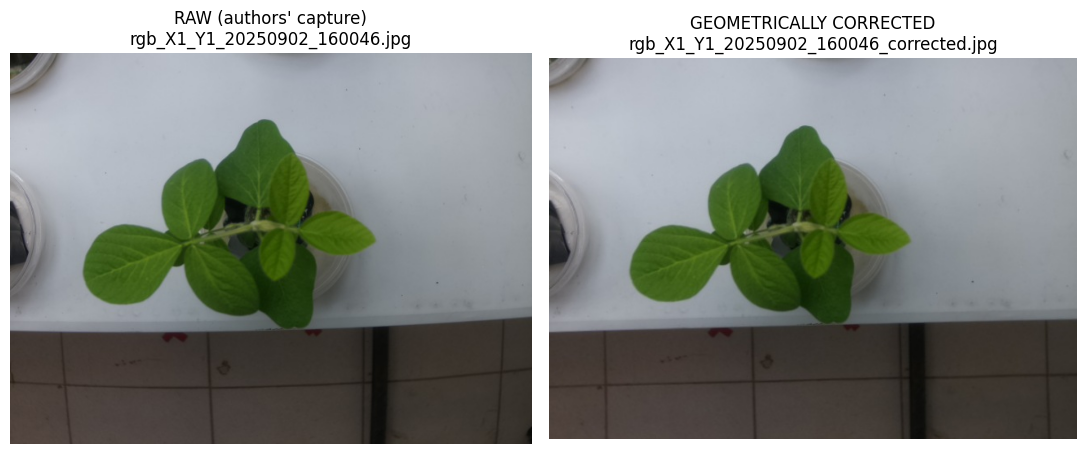

Sample provenance: Mendeley 10.17632/n4cbs5kd8v.2, data/experiment.zip: experiment/2025-09-02_16h/picam/rgb_X1_Y1_20250902_160046.jpg


In [ ]:
sample = sorted(CORRECTED_DIR.glob("rgb_X1_Y1_*_corrected.jpg"))[0]
raw_name = sample.name.replace("_corrected", "")
raw_path = next(p for p in rgb_paths if p.name == raw_name)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].imshow(cv2.cvtColor(cv2.imread(str(raw_path)), cv2.COLOR_BGR2RGB))
axes[0].set_title(f"RAW (authors' capture)\n{raw_name}")
axes[1].imshow(cv2.cvtColor(cv2.imread(str(sample)), cv2.COLOR_BGR2RGB))
axes[1].set_title(f"GEOMETRICALLY CORRECTED\n{sample.name}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Sample provenance: Mendeley 10.17632/n4cbs5kd8v.2, data/experiment.zip:", raw_path.relative_to(EXPERIMENT_DIR))

## 3. U-Net plant segmentation with the authors' pre-trained weights (paper Step 2)

The authors' model is `smp.Unet` with a ResNet34 encoder, 2 classes, trained for 50 epochs
on 100 Supervisely-labelled images (paper Section 7.1). The released
`plant_segmentation_model.pth` is a dict with `model_state_dict`, `model_config`,
`img_size = 512` and ImageNet `normalization` (per the authors' training notebook,
`2_plant_segmentation_training.ipynb`). We rebuild the architecture from the checkpoint's
own `model_config`; one documented adaptation: `encoder_weights=None` (no ImageNet download
— every weight is then overwritten by the checkpoint anyway). **日本語:** 著者の学習済み
U-Net重みを読み込みます（ImageNet事前学習のダウンロードは省略）。

In [ ]:
MODEL_PATH = str(DATA_DIR / "plant_segmentation_model.pth")
checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)  # author call
print("Checkpoint keys:", sorted(checkpoint.keys()))
print("model_config:", checkpoint["model_config"], "| img_size:", checkpoint["img_size"])
cfg = checkpoint["model_config"]
model = smp.Unet(
    encoder_name=cfg["encoder_name"],      # 'resnet34'
    encoder_weights=None,                  # ADAPTATION: no imagenet download; checkpoint overwrites all weights
    in_channels=cfg["in_channels"],
    classes=cfg["classes"],
    activation=None,
)
result = model.load_state_dict(checkpoint["model_state_dict"], strict=True)
print("missing keys:", result.missing_keys, "| unexpected keys:", result.unexpected_keys)
print("checkpoint normalization:", checkpoint["normalization"])
model = model.to(device).eval()
print("State dict loaded (strict). Parameters:", sum(p.numel() for p in model.parameters()))

Checkpoint keys: ['img_size', 'model_config', 'model_state_dict', 'normalization']
model_config: {'encoder_name': 'resnet34', 'encoder_weights': 'imagenet', 'in_channels': 3, 'classes': 2} | img_size: 512


missing keys: [] | unexpected keys: []
checkpoint normalization: {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}
State dict loaded (strict). Parameters: 24436514


### Batch inference over all 528 corrected captures

The `segment_image` / `process_folder` functions below are **copied verbatim** from the
authors' `2_plant_segmentation_training.ipynb` inference section: resize to 512×512,
ImageNet normalization, argmax, nearest-neighbour resize back to 640×480, masks saved as
`{name}_segmented_mask.png` (0/255 PNG). Inference runs in eval mode under `torch.no_grad()`,
so results are identical on CPU and GPU. **Expected:** 528 masks in
`/content/work/processed_rgb_masks`. **日本語:** 528枚を推論し、マスクを保存します。

In [ ]:
# --- Exact author code: image_processing/rgb/2_plant_segmentation_training.ipynb, inference cell ---
def segment_image(model, image_path, device, img_size=512):
    """Segments a single image and returns the binary mask at original resolution."""
    model.eval()
    original = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h, w = original.shape[:2]

    transform = A.Compose([
        A.Resize(img_size, img_size),
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2(),
    ])
    tensor = transform(image=original)['image'].unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(tensor).argmax(dim=1).squeeze().cpu().numpy()

    return cv2.resize(pred.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)


def process_folder(model, input_folder, output_folder, device, img_size=512):
    """Segments all images in a folder. Masks are saved as lossless PNG."""
    os.makedirs(output_folder, exist_ok=True)

    image_paths = sorted(
        glob(os.path.join(input_folder, '**', '*.jpg'),  recursive=True) +
        glob(os.path.join(input_folder, '**', '*.jpeg'), recursive=True) +
        glob(os.path.join(input_folder, '**', '*.png'),  recursive=True)
    )
    print(f'Processing {len(image_paths)} images...')

    for img_path in tqdm(image_paths):
        name = os.path.splitext(os.path.basename(img_path))[0]
        mask_path = os.path.join(output_folder, name + '_segmented_mask.png')
        try:
            mask = segment_image(model, img_path, device, img_size)
            cv2.imwrite(mask_path, mask * 255)
        except Exception as e:
            print(f'Error processing {os.path.basename(img_path)}: {e}')

    print(f'\nDone. {len(image_paths)} masks saved to: {output_folder}')

Run the authors' batch inference on the corrected folder. On T4 this takes about one to
three minutes; on CPU roughly 15–30 minutes. **日本語:** 実行環境により数分〜30分程度です。

In [ ]:
MASKS_DIR = Path("/content/work/processed_rgb_masks")
t0 = time.time()
process_folder(model, str(CORRECTED_DIR), str(MASKS_DIR), device, checkpoint["img_size"])
dt = time.time() - t0
masks = sorted(MASKS_DIR.glob("*_segmented_mask.png"))
print(f"Inference wall time: {dt:.1f} s ({dt/len(rgb_paths):.2f} s/image) on {device}")
assert len(masks) == 528, f"expected 528 masks, found {len(masks)}"


Processing 528 images...


  0%|          | 0/528 [00:00<?, ?it/s]


Done. 528 masks saved to: /content/work/processed_rgb_masks
Inference wall time: 23.7 s (0.04 s/image) on cuda


### Prediction preview — corrected input with U-Net mask overlay

One irrigated (`X4_Y3`, R) and one drought (`X6_Y1`, S) plant from the first and last
sessions. **The green overlay is the model's prediction, not a human annotation** (no
pixel-level reference annotations are shipped with the dataset). **日本語:** 緑のオーバーレイは
U-Netの予測マスクです（人手アノテーションではありません）。

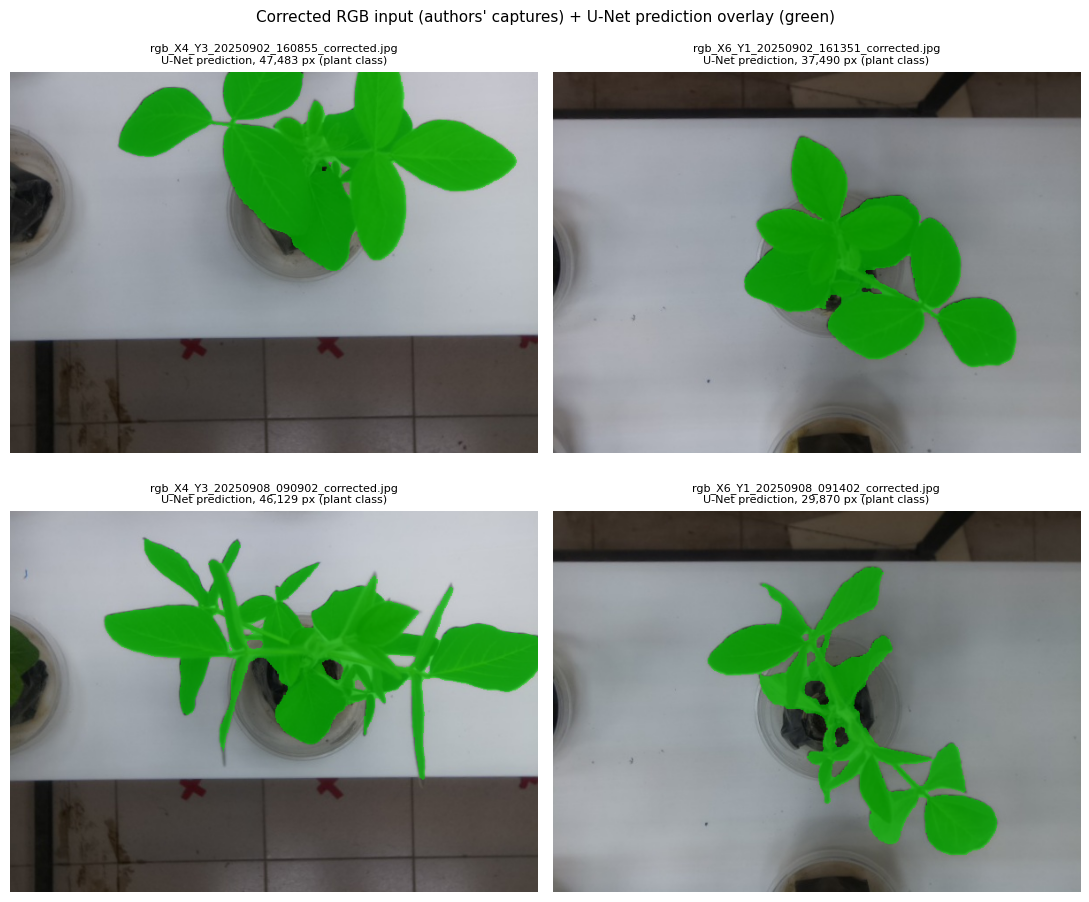

In [ ]:
def sess_date(s):
    return s.split("_")[0].replace("-", "")

def show_prediction(stem_base):
    corr = CORRECTED_DIR / f"{stem_base}_corrected.jpg"
    mask = MASKS_DIR / f"{stem_base}_corrected_segmented_mask.png"
    img = cv2.cvtColor(cv2.imread(str(corr)), cv2.COLOR_BGR2RGB)
    m = cv2.imread(str(mask), cv2.IMREAD_GRAYSCALE) > 127
    overlay = img.copy(); overlay[m] = (0.45 * img[m] + 0.55 * np.array([0, 230, 0])).astype(np.uint8)
    return img, overlay, m.sum(), corr.name

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
first_s, last_s = sessions[0], sessions[-1]
for row, sess in enumerate([first_s, last_s]):
    for col, coord in enumerate(["rgb_X4_Y3", "rgb_X6_Y1"]):
        stem = sorted(CORRECTED_DIR.glob(f"{coord}_{sess_date(sess)}_*_corrected.jpg"))[0].stem[:-10]
        img, overlay, area_px, name = show_prediction(stem)
        axes[row, col].imshow(overlay)
        axes[row, col].set_title(f"{name}\nU-Net prediction, {area_px:,} px (plant class)", fontsize=8)
        axes[row, col].axis("off")
plt.suptitle("Corrected RGB input (authors' captures) + U-Net prediction overlay (green)", fontsize=11)
plt.tight_layout(); plt.show()

## 4. Mask post-processing — adaptive bounding box v5 (paper Step 3)

**Copied verbatim** from the authors' `3_mask_postprocessing_adaptive_bbox.ipynb` (v5):
label connected components, keep the component with maximum overlap with the central 60%
ROI, then keep secondary components only if (A) within `bridge_radius=10` px of the central
plant or (B) their centroid lies inside the central plant's bbox expanded by
`BBOX_MARGIN=140` px **and** ≥ `MIN_OVERLAP=0.95` of their pixels overlap that bbox —
the configuration values the authors' notebook sets. No new pixels are created; only whole
components are discarded. **日本語:** 著者の後処理（適応的バウンディングボックス v5）を
そのまま適用し、隣接植物の混入を除去します。

In [ ]:
# --- Exact author code: image_processing/rgb/3_mask_postprocessing_adaptive_bbox.ipynb (v5 function) ---
def postprocess_mask(mask, roi_frac=0.6, bridge_radius=10, bbox_margin=40,
                     min_overlap_ratio=0.5):
    """
    Conservative post-processing v5 — adaptive bounding box.

    Decision rules for secondary components:
    1. If minimum distance to the central component <= bridge_radius -> KEEP
       (likely a disconnected fragment of the same plant).
    2. If centroid is inside the expanded bbox AND at least min_overlap_ratio
       of its pixels overlap the bbox -> KEEP.
    3. Otherwise -> DISCARD.

    Parameters
    ----------
    mask : ndarray (2-D, binary 0/1)
    roi_frac : float
        Fraction of the image defining the central ROI used to identify the
        central plant (default 0.6 = central 60%).
    bridge_radius : int
        Maximum distance (px) between a component and the central plant for
        it to be considered part of the same individual (default 10).
    bbox_margin : int
        Expansion of the central plant bounding box in pixels (default 40).
    min_overlap_ratio : float
        Minimum fraction of a secondary component's pixels that must fall
        inside the expanded bbox to retain it (default 0.5).
    """
    labeled, num_features = ndimage.label(mask)
    if num_features <= 1:
        return mask

    h, w = mask.shape

    # Central ROI (only used to identify the central plant)
    roi_h = int(h * roi_frac)
    roi_w = int(w * roi_frac)
    y0 = (h - roi_h) // 2
    y1 = y0 + roi_h
    x0 = (w - roi_w) // 2
    x1 = x0 + roi_w

    roi_mask = np.zeros_like(mask, dtype=bool)
    roi_mask[y0:y1, x0:x1] = True

    # Identify central plant: component with maximum overlap with the ROI
    intersections = []
    for i in range(1, num_features + 1):
        comp = (labeled == i)
        intersections.append((np.logical_and(comp, roi_mask).sum(), i))

    central_label = max(intersections)[1]
    central_mask  = (labeled == central_label)

    # Adaptive bounding box of the central plant
    ys, xs = np.where(central_mask)
    bbox_y0 = max(0, ys.min() - bbox_margin)
    bbox_y1 = min(h, ys.max() + bbox_margin)
    bbox_x0 = max(0, xs.min() - bbox_margin)
    bbox_x1 = min(w, xs.max() + bbox_margin)

    bbox_mask = np.zeros_like(mask, dtype=bool)
    bbox_mask[bbox_y0:bbox_y1, bbox_x0:bbox_x1] = True

    # Distance map to the central plant
    dist_map = ndimage.distance_transform_edt(~central_mask)

    # Filter secondary components
    result = np.zeros_like(mask, dtype=mask.dtype)

    for i in range(1, num_features + 1):
        comp = (labeled == i)

        if i == central_label:
            result[comp] = 1
            continue

        # Rule A: direct proximity
        if dist_map[comp].min() <= bridge_radius:
            result[comp] = 1
            continue

        # Rule B: centroid inside expanded bbox + sufficient overlap
        cy, cx = ndimage.center_of_mass(comp)
        if (bbox_y0 <= cy <= bbox_y1) and (bbox_x0 <= cx <= bbox_x1):
            overlap   = np.logical_and(comp, bbox_mask).sum()
            comp_area = comp.sum()
            if (overlap / comp_area) >= min_overlap_ratio:
                result[comp] = 1

    return result

Apply v5 post-processing to all 528 masks with the authors' configuration values
(`BBOX_MARGIN=140`, `MIN_OVERLAP=0.95`), writing to `processed_rgb_masks_post` and
reporting how many masks changed. **Expected:** a small-to-moderate share of masks
corrected (neighbouring-plant removal). **日本語:** 全マスクに後処理を適用し、
変化した枚数を報告します。

In [ ]:
POST_DIR = Path("/content/work/processed_rgb_masks_post"); POST_DIR.mkdir(parents=True, exist_ok=True)
BBOX_MARGIN = 140    # authors' notebook config
MIN_OVERLAP = 0.95   # authors' notebook config
stats = {"unchanged": 0, "corrected": 0, "errors": 0}
areas_before, areas_after = [], []
t0 = time.time()
for mask_path in tqdm(sorted(MASKS_DIR.glob("*_segmented_mask.png")), desc="Post-processing"):
    try:
        mask_binary = (cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
        mask_post = postprocess_mask(mask_binary, bbox_margin=BBOX_MARGIN, min_overlap_ratio=MIN_OVERLAP)
        if np.array_equal(mask_binary, mask_post): stats["unchanged"] += 1
        else: stats["corrected"] += 1
        cv2.imwrite(str(POST_DIR / mask_path.name), mask_post * 255)
        areas_before.append(int(mask_binary.sum())); areas_after.append(int(mask_post.sum()))
    except Exception as e:
        stats["errors"] += 1; print(f"Error in {mask_path.name}: {e}")
ab, aa = np.array(areas_before), np.array(areas_after)
red = (ab - aa) / (ab + 1e-6) * 100
print(f"Processed {len(areas_before)} masks in {time.time()-t0:.1f} s | {stats}")
print(f"Mean area before {ab.mean():.0f} px, after {aa.mean():.0f} px, mean reduction {red.mean():.2f}%")
assert stats["errors"] == 0

Post-processing:   0%|          | 0/528 [00:00<?, ?it/s]

Processed 528 masks in 3.7 s | {'unchanged': 527, 'corrected': 1, 'errors': 0}
Mean area before 36514 px, after 36514 px, mean reduction 0.00%


### Post-processed preview and area comparison

Same two plants as above, now with the **post-processed** mask (authors' Step-3 output),
plus the authors' before/after area diagnostics. **日本語:** 後処理後のマスクと面積比較です。

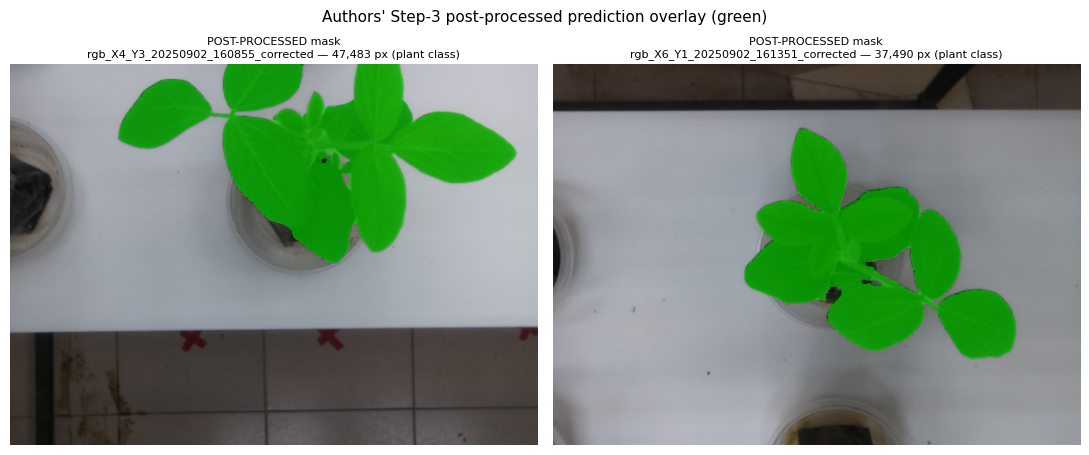

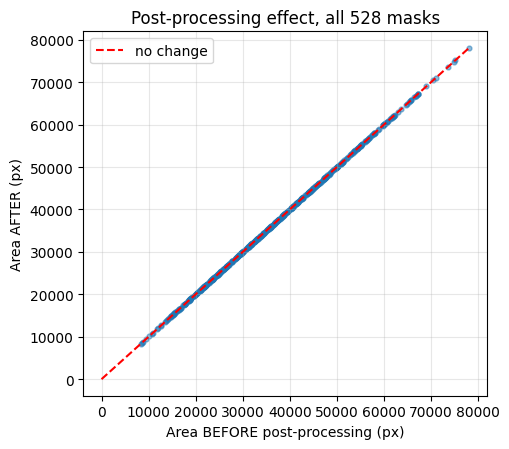

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for col, coord in enumerate(["rgb_X4_Y3", "rgb_X6_Y1"]):
    stem = sorted(CORRECTED_DIR.glob(f"{coord}_{sess_date(sessions[0])}_*_corrected.jpg"))[0].stem[:-10]
    img = cv2.cvtColor(cv2.imread(str(CORRECTED_DIR / f"{stem}_corrected.jpg")), cv2.COLOR_BGR2RGB)
    m = cv2.imread(str(POST_DIR / f"{stem}_corrected_segmented_mask.png"), cv2.IMREAD_GRAYSCALE) > 127
    overlay = img.copy(); overlay[m] = (0.45 * img[m] + 0.55 * np.array([0, 230, 0])).astype(np.uint8)
    axes[col].imshow(overlay)
    axes[col].set_title(f"POST-PROCESSED mask\n{stem}_corrected — {m.sum():,} px (plant class)", fontsize=8)
    axes[col].axis("off")
plt.suptitle("Authors' Step-3 post-processed prediction overlay (green)", fontsize=11)
plt.tight_layout(); plt.show()

max_val = max(ab.max(), aa.max())
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.scatter(ab, aa, s=12, alpha=0.5)
ax.plot([0, max_val], [0, max_val], "r--", label="no change")
ax.set_xlabel("Area BEFORE post-processing (px)"); ax.set_ylabel("Area AFTER (px)")
ax.set_title("Post-processing effect, all 528 masks"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5. Per-plant projected leaf area time series (paper Step 4 / Section 7.1, Fig. 19)

Below, `TREATMENT_MAP`, `parse_filename` and `calculate_mask_area` are **copied verbatim**
from the authors' `image_processing/rgb/4_leaf_area_temporal_analysis.py`: area is the
count of non-black pixels of each mask; treatment (R/S) is resolved from the plant
coordinates via the authors' fixed grid assignment. **日本語:** 著者コードのまま、
マスクの非黒ピクセル数を葉面積（ピクセル）として集計します。

In [ ]:
# --- Exact author code: image_processing/rgb/4_leaf_area_temporal_analysis.py lines 27-97 ---
TREATMENT_MAP = {
    'X1_Y1': 'R', 'X1_Y2': 'S', 'X1_Y3': 'R', 'X1_Y4': 'S',
    'X2_Y1': 'S', 'X2_Y2': 'R', 'X2_Y3': 'S', 'X2_Y4': 'R',
    'X3_Y1': 'S', 'X3_Y2': 'R', 'X3_Y3': 'R', 'X3_Y4': 'S',
    'X4_Y1': 'R', 'X4_Y2': 'S', 'X4_Y3': 'R', 'X4_Y4': 'R',
    'X5_Y1': 'S', 'X5_Y2': 'R', 'X5_Y3': 'S', 'X5_Y4': 'R',
    'X6_Y1': 'S', 'X6_Y2': 'R', 'X6_Y3': 'S', 'X6_Y4': 'S',
}

def parse_filename(filename):
    """
    Extracts metadata from the filename.
    Supports two formats:
      - {R|S}_rgb_{X}_{Y}_{Date}_{Time}_{suffix}_segmented_mask.png
      - rgb_{X}_{Y}_{Date}_{Time}_{suffix}_segmented_mask.png
    When the treatment prefix is absent, it is inferred from TREATMENT_MAP.
    """
    # Format with treatment prefix
    pattern_full = r'^([RS])_rgb_(X\d+)_(Y\d+)_(\d{8})_(\d{6})_\w+_segmented_mask\.png$'
    # Format without treatment prefix
    pattern_no_prefix = r'^rgb_(X\d+)_(Y\d+)_(\d{8})_(\d{6})_\w+_segmented_mask\.png$'

    match = re.match(pattern_full, filename)
    if match:
        group = match.group(1)
        x = match.group(2)
        y = match.group(3)
        date_str = match.group(4)
        time_str = match.group(5)
    else:
        match = re.match(pattern_no_prefix, filename)
        if match:
            x = match.group(1)
            y = match.group(2)
            date_str = match.group(3)
            time_str = match.group(4)
            coord = f"{x}_{y}"
            group = TREATMENT_MAP.get(coord)
            if group is None:
                print(f"  Warning: unknown coordinates {coord} in {filename}")
                return None
        else:
            return None

    plant_id = f"{group}_{x}_{y}"
    datetime_obj = datetime.strptime(f"{date_str}_{time_str}", "%Y%m%d_%H%M%S")

    return {
        'group': group,
        'plant_id': plant_id,
        'x': x,
        'y': y,
        'datetime': datetime_obj,
        'date': datetime_obj.date(),
    }

def calculate_mask_area(filepath):
    """
    Calculates mask area by counting non-black pixels.
    """
    img = Image.open(filepath)
    img_array = np.array(img)

    # If RGB/RGBA, check any channel > 0
    if len(img_array.shape) == 3:
        area = np.sum(np.any(img_array > 0, axis=-1))
    else:
        # Grayscale image
        area = np.sum(img_array > 0)

    return int(area)


Run the authors' mask-processing loop over the 528 post-processed masks and build the
records table (`plant_id`, treatment group, coordinates, timestamp, `area_pixels`).
**Expected:** 528 records, 12 R + 12 S plants. **日本語:** 528マスクを解析し、
24植物（R12/S12）の時系列テーブルを作成します。

In [ ]:
MASKS_ANALYSIS_DIR = str(POST_DIR)
records = []
files = sorted(os.listdir(MASKS_ANALYSIS_DIR))
print(f"Processing {len(files)} masks...")
for filename in tqdm(files):
    if not filename.endswith(".png"): continue
    info = parse_filename(filename)
    if info is None:
        print(f"  Warning: could not parse {filename}"); continue
    area = calculate_mask_area(os.path.join(MASKS_ANALYSIS_DIR, filename))
    records.append({"plant_id": info["plant_id"], "group": info["group"],
                    "coordinates": f"{info['x']}_{info['y']}", "datetime": info["datetime"],
                    "date": info["date"], "area_pixels": area})
df = pd.DataFrame(records).sort_values(["plant_id", "datetime"]).reset_index(drop=True)
assert len(df) == 528, f"expected 528 records, got {len(df)}"
print("Plants:", df.plant_id.nunique(), "| R:", df[df.group=='R'].plant_id.nunique(),
      "| S:", df[df.group=='S'].plant_id.nunique())
df.head(8)

Processing 528 masks...


  0%|          | 0/528 [00:00<?, ?it/s]

Plants: 24 | R: 12 | S: 12


,plant_id,group,coordinates,datetime,date,area_pixels
0,R_X1_Y1,R,X1_Y1,2025-09-02 16:00:46,2025-09-02,34766
1,R_X1_Y1,R,X1_Y1,2025-09-02 21:00:45,2025-09-02,20290
2,R_X1_Y1,R,X1_Y1,2025-09-03 07:00:45,2025-09-03,36616
3,R_X1_Y1,R,X1_Y1,2025-09-03 12:00:45,2025-09-03,39337
4,R_X1_Y1,R,X1_Y1,2025-09-03 16:00:46,2025-09-03,39318
5,R_X1_Y1,R,X1_Y1,2025-09-03 21:00:45,2025-09-03,24735
6,R_X1_Y1,R,X1_Y1,2025-09-04 07:00:45,2025-09-04,39548
7,R_X1_Y1,R,X1_Y1,2025-09-04 12:01:01,2025-09-04,42465


### Temporal leaf-area figure (authors' Step-4 plot)

The authors' `create_plot` colour scheme — blue tones for irrigated (R), red tones for
drought (S), one line per plant — is reproduced below; the only adaptation is PNG display
instead of the authors' 300-dpi TIFF export. This is the notebook analogue of the paper's
Fig. 19 (generated here from the released data, not copied from the paper).
**日本語:** 著者のStep-4プロット（R=青系、S=赤系）をPNGで再現します。

In [ ]:
# --- Author create_plot (image_processing/rgb/4_leaf_area_temporal_analysis.py), adapted TIFF->PNG ---
import matplotlib.cm as cm
def create_plot(df):
    """
    Creates the area vs. time plot with colour-coded treatment groups.
    """
    fig, ax = plt.subplots(figsize=(14, 8))

    # Unique plants per group
    plants_R = sorted(df[df['group'] == 'R']['plant_id'].unique())
    plants_S = sorted(df[df['group'] == 'S']['plant_id'].unique())

    n_R = len(plants_R)
    n_S = len(plants_S)

    # Blue palette for irrigated (R)
    colors_blue = cm.Blues(np.linspace(0.3, 0.9, n_R))
    # Red palette for drought (S)
    colors_red = cm.Reds(np.linspace(0.3, 0.9, n_S))

    # Plot irrigated plants (R) – blue tones
    for i, plant in enumerate(plants_R):
        plant_data = df[df['plant_id'] == plant].sort_values('datetime')
        ax.plot(plant_data['datetime'], plant_data['area_pixels'],
                color=colors_blue[i], linewidth=1.5, alpha=0.8,
                label=plant, marker='o', markersize=3)

    # Plot drought plants (S) – red tones
    for i, plant in enumerate(plants_S):
        plant_data = df[df['plant_id'] == plant].sort_values('datetime')
        ax.plot(plant_data['datetime'], plant_data['area_pixels'],
                color=colors_red[i], linewidth=1.5, alpha=0.8,
                label=plant, marker='s', markersize=3)

    # Axis labels and title
    ax.set_xlabel('Date and Time', fontsize=12)
    ax.set_ylabel('Area (pixels)', fontsize=12)
    ax.set_title('Temporal evolution of projected leaf area (zenithal view)\nBlue: Irrigated (R) | Red: Drought (S)', fontsize=14)

    plt.xticks(rotation=45, ha='right')

    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8,
              ncol=2, title='Plants')

    plt.tight_layout()

    # ADAPTATION: authors' script saved 300-dpi TIFF; here lossless PNG so the
    # figure is viewable in the notebook and in the published preview.
    fig.savefig(OUTPUT_PLOT, format='png', dpi=300, bbox_inches='tight')
    print(f"Plot saved: {OUTPUT_PLOT}")

    plt.close()


Display the figure (the copied function writes `leaf_area_temporal.png`); we also save
the authors' CSV, `leaf_area_temporal.csv`, next to it. **日本語:** 図を表示し、
著者と同じCSVを保存します。

Plot saved: /content/work/leaf_area_results/leaf_area_temporal.png


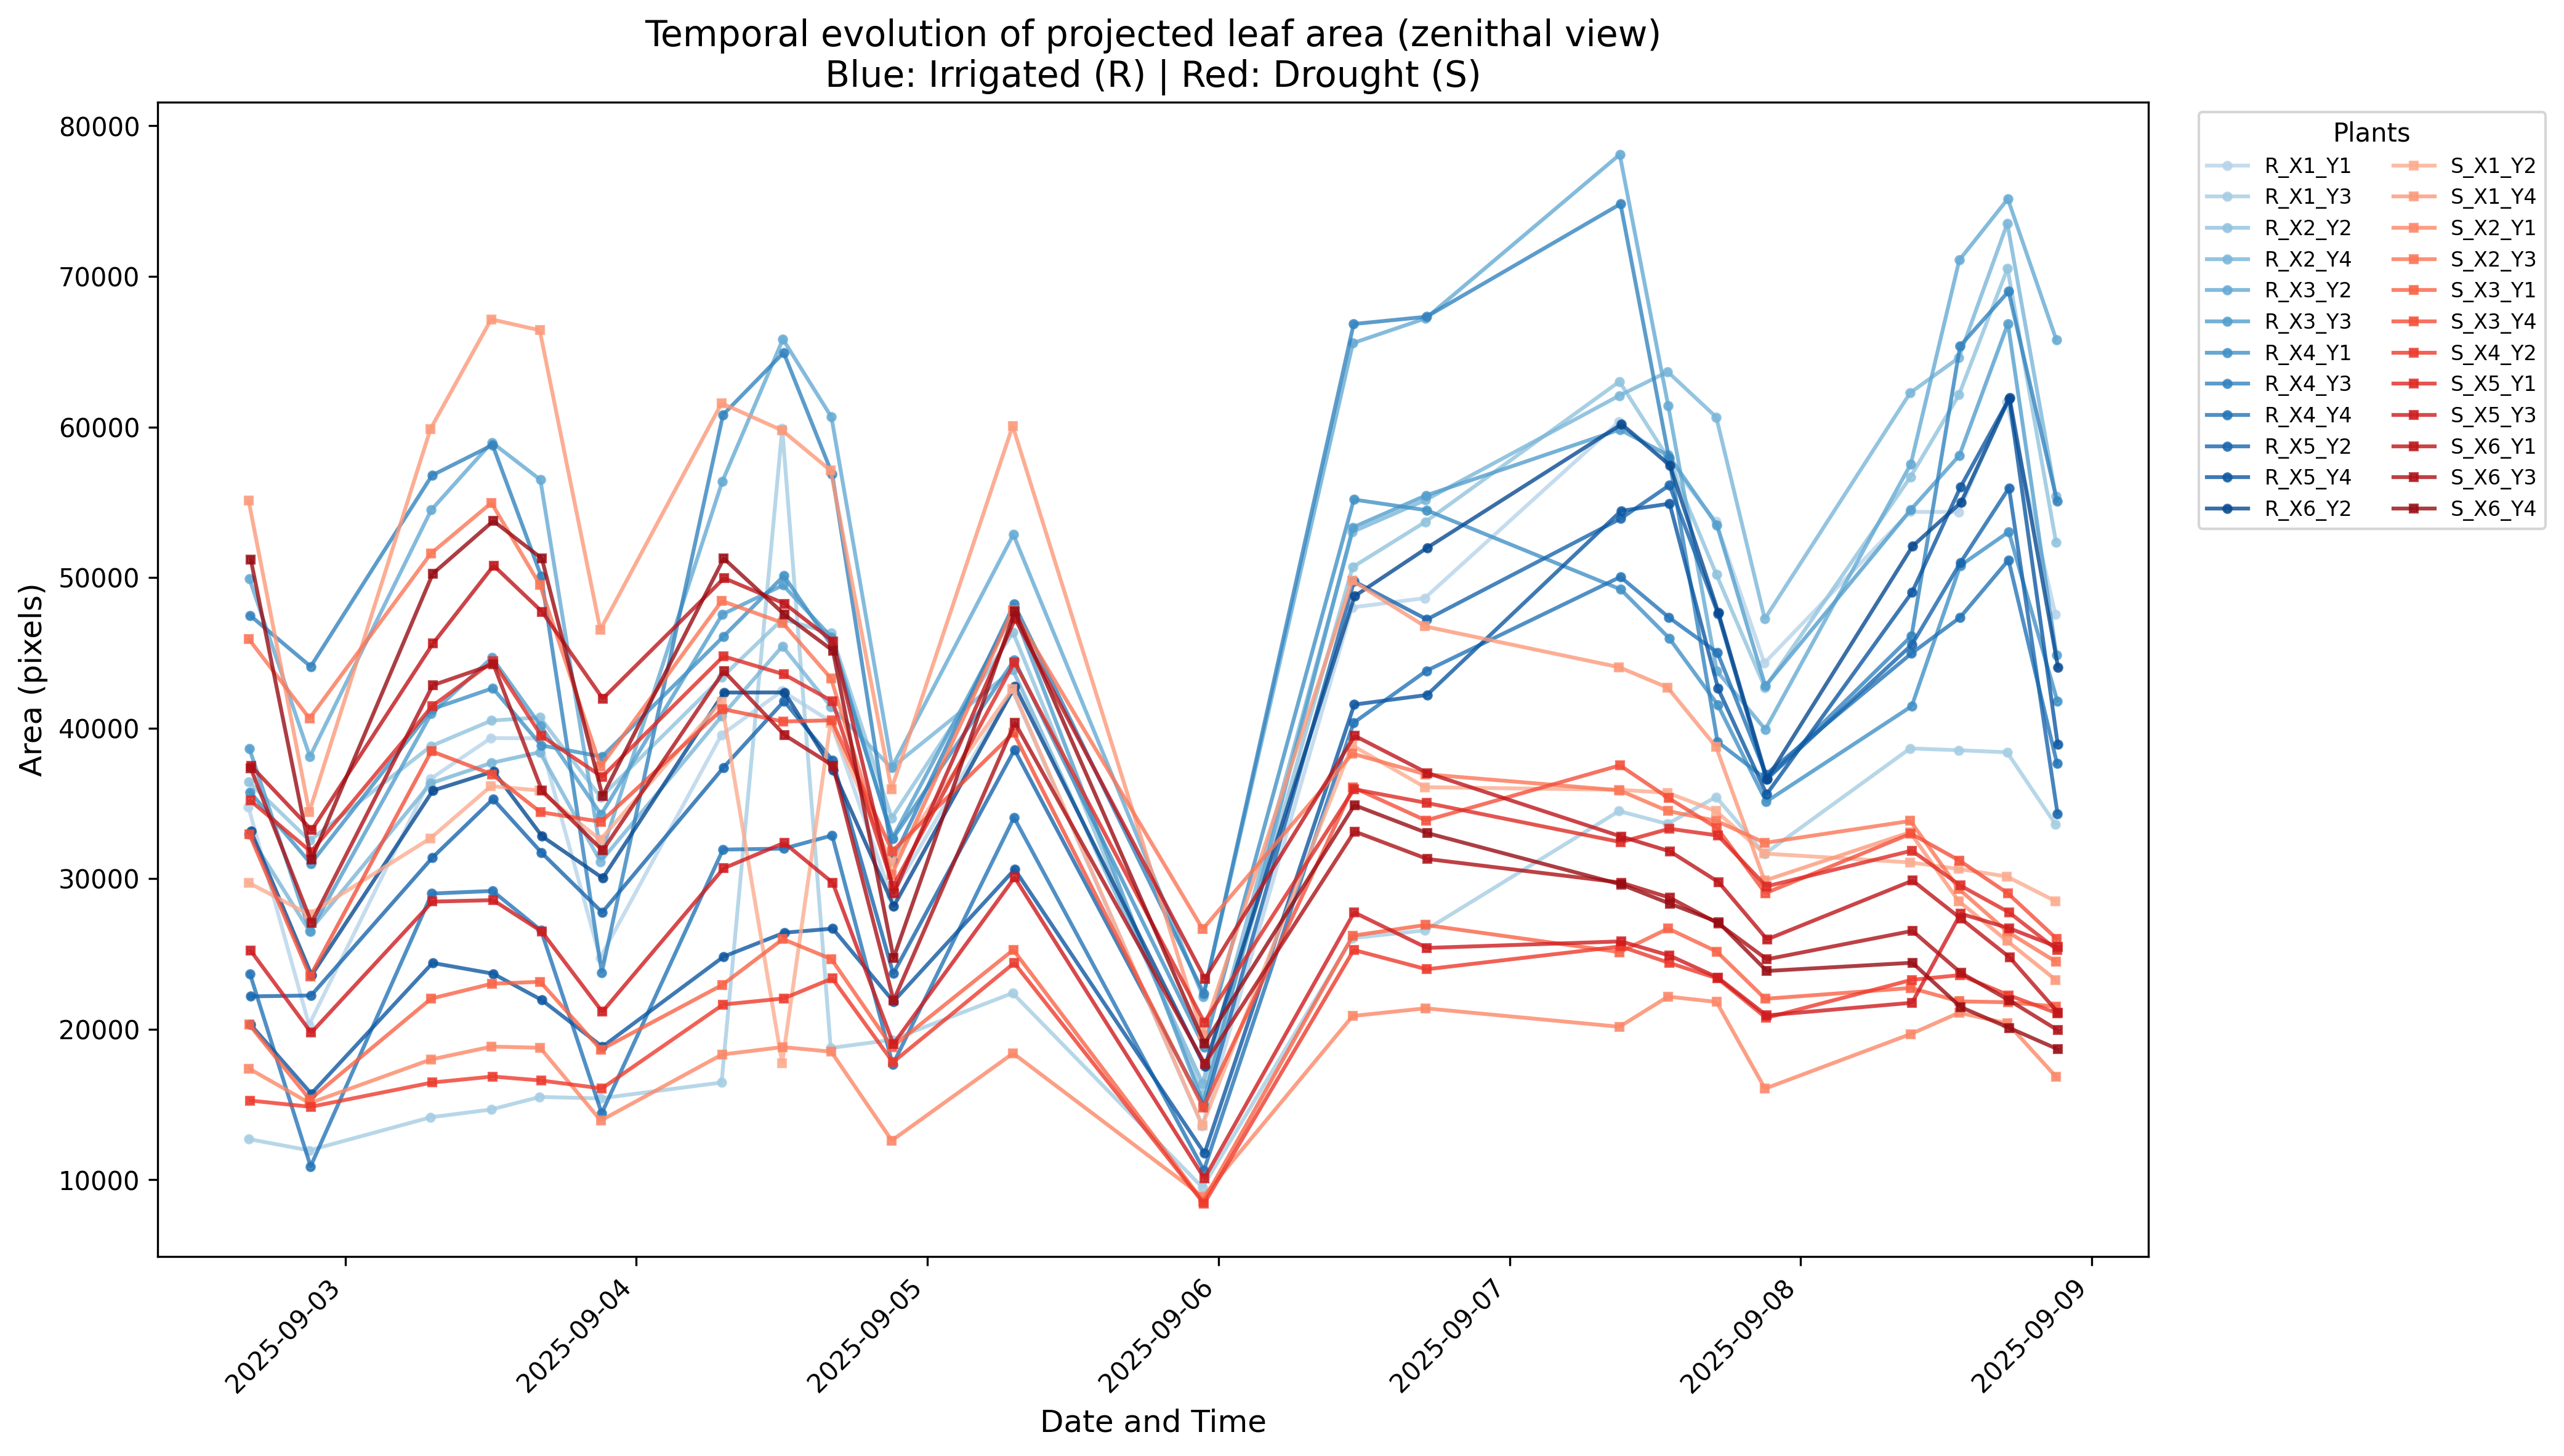

CSV saved: /content/work/leaf_area_results/leaf_area_temporal.csv (528 records)


In [ ]:
RESULTS_DIR = Path("/content/work/leaf_area_results"); RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_PLOT = str(RESULTS_DIR / "leaf_area_temporal.png")
OUTPUT_CSV = str(RESULTS_DIR / "leaf_area_temporal.csv")
create_plot(df)
df.to_csv(OUTPUT_CSV, index=False)
from IPython.display import Image as IPyImage, display
display(IPyImage(OUTPUT_PLOT))
print("CSV saved:", OUTPUT_CSV, f"({len(df)} records)")

### Treatment summary

Small quantitative check of the executed example: per-treatment mean projected leaf area at
the first and last session day (this notebook's own summary — the paper publishes the result
graphically only, so no numeric reference values exist to compare against).
**日本語:** 最初と最終セッションの処理群別平均葉面積（本ノートブック独自の集計）。

In [ ]:
# First/last session DAY (several capture sessions share a date; captures within one
# session carry distinct HHMMSS stamps, so filtering on the exact timestamp would keep
# only a single plant).
first_day = df[df.date == df.date.min()]
last_day = df[df.date == df.date.max()]
summary = pd.DataFrame({
    "first_session_area_px": first_day.groupby("group").area_pixels.mean().round(0),
    "last_session_area_px": last_day.groupby("group").area_pixels.mean().round(0),
    "n_plants": last_day.groupby("group").plant_id.nunique(),
})
summary["mean_growth_x"] = (last_day.groupby("group").area_pixels.mean()
                            / first_day.groupby("group").area_pixels.mean()).round(2)
print("Sessions:", df.datetime.min(), "->", df.datetime.max())
summary

Sessions: 2025-09-02 16:00:46 -> 2025-09-08 21:13:57


,first_session_area_px,last_session_area_px,n_plants,mean_growth_x
group,,,,
R,28806.0,53498.0,12,1.86
S,29903.0,25341.0,12,0.85


## 6. Interpretation, differences from the paper, and validation record

**What was reproduced (executed on Colab, all outputs above are from this run):**
the authors' full RGB branch — geometric correction (their calibration, their OpenCV
operations), U-Net/ResNet34 inference with their released 94 MB checkpoint, their v5
adaptive-bbox post-processing (BBOX_MARGIN=140, MIN_OVERLAP=0.95), and their Step-4
per-plant leaf-area aggregation over all 528 released captures (24 plants × 22 sessions).

**Qualitative expectation vs. the paper (Fig. 19):** irrigated (R) plants keep growing
across the 7 days while drought (S) plants' projected leaf area plateaus or lags; the
executed figure should show red curves flattening relative to blue ones. The paper reports
segmentation validation IoU 0.95 / Dice 0.975; the authors publish **no numerical result
tables**, so no quantitative comparison beyond this qualitative check is possible.

**Differences from the authors' workflow (all documented at the relevant cells):**
GUI dialogs replaced by fixed Colab paths; `encoder_weights=None` at model build; PNG
outputs instead of 300-dpi TIFF; the authors' Google-Drive-mount instructions replaced by
direct Mendeley downloads. The scientific operations are the authors' own code.

**Known limitations:** one-example-scope check — this is not a re-training or a benchmark
reproduction; mask quality depends on the authors' model; residual masks were *not*
hand-edited in Napari (paper's optional Step 5 / thermal-side manual curation is out of
scope); area is in pixels (the authors' script also reports pixels only).

**Provenance:** paper HardwareX 28:e00846 (PMC13677040, CC BY 4.0); code+data Mendeley
Data 10.17632/n4cbs5kd8v version 2 (2026-09-06, CC BY-SA 4.0); PhenoPaper investigation
`p-a686209c837f9985acc05f1403009a48-20261022T122811Z-2664979` used as research guidance
only. **日本語:** 本ノートブックは著者公開コード・データのみで構成され、上記の適応箇所以外は
著者コードをそのまま使用しています。